#Iris Flower Classification :-

#Step1 :- Import required libraries

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
print("Libraries imported successfully!")

Libraries imported successfully!


#Step2 :- Load the dataset

In [37]:
# Load Iris dataset :-
iris = load_iris()
print("Dataset loaded successfully!")

Dataset loaded successfully!


#Step 3 – Convert dataset into a DataFrame

In [38]:
# Create a DataFrame :-
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)
# Add flower species column :-
df["Species"] = iris.target
# Convert numerical labels into flower names :-
df["Species"] = df["Species"].map(
    {0: "Setosa", 1: "Versicolor", 2: "Virginica"}
)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


#Step 4 – Understand the dataset

In [39]:
# Display first five records :-
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  Setosa  
1  Setosa  
2  Setosa  
3  Setosa  
4  Setosa  


In [40]:
# Check total rows and columns :-
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(150, 5)


In [41]:
# Check column information :-
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [42]:
# Statistical summary :-
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


#Step 5 – Check missing values and duplicates

In [43]:
# Check missing values :-
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Species              0
dtype: int64


In [44]:
# Check duplicate records :-
print("\nDuplicate Records:")
print(df.duplicated().sum())


Duplicate Records:
1


In [45]:
# Remove duplicate records :-
df = df.drop_duplicates().reset_index(drop=True)
print("New dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

New dataset shape: (149, 5)
Remaining duplicates: 0


#Step 6 – Exploratory Data Analysis (EDA)

In [46]:
#Count flowers in each category :-
print(df["Species"].value_counts())

Species
Setosa        50
Versicolor    50
Virginica     49
Name: count, dtype: int64


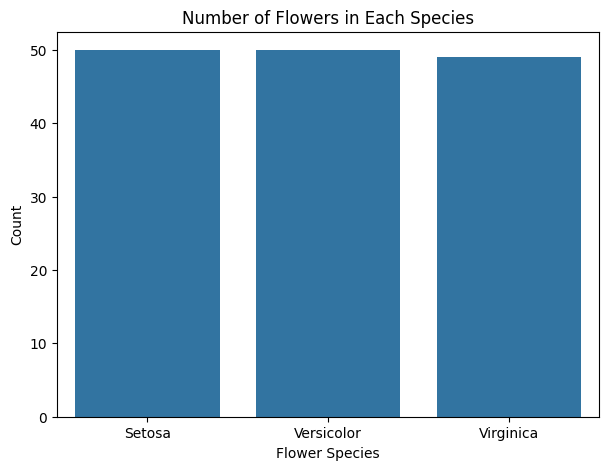

In [47]:
#Create a bar chart :-
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Species")
plt.title("Number of Flowers in Each Species")
plt.xlabel("Flower Species")
plt.ylabel("Count")
plt.show()

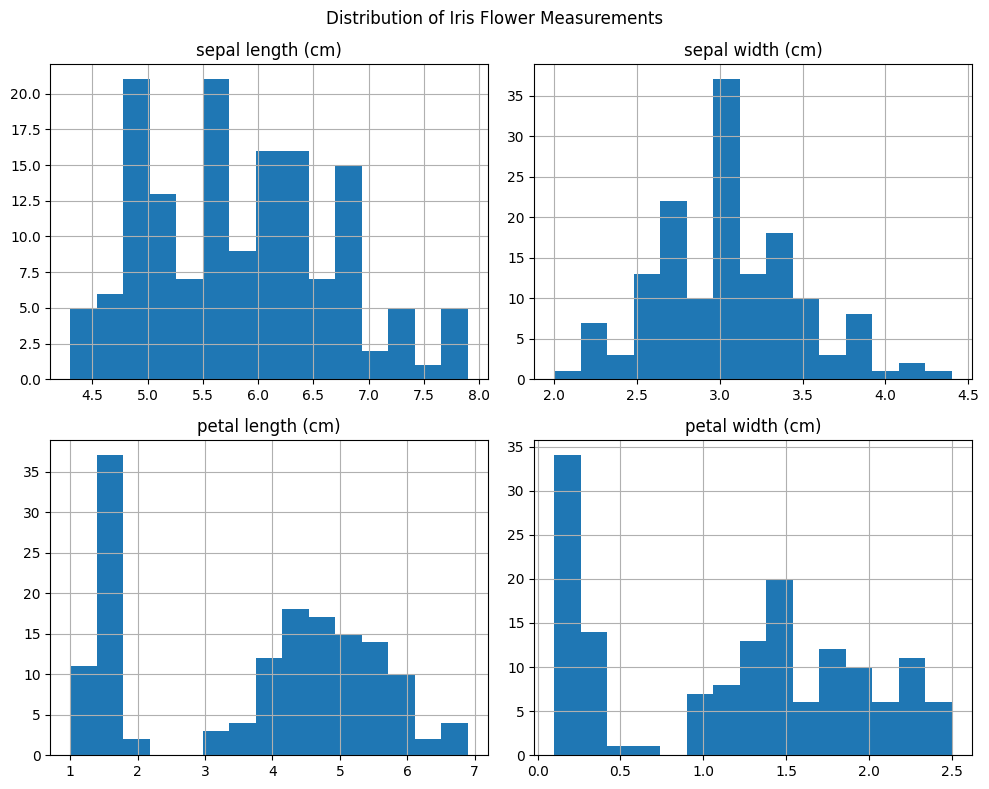

In [48]:
#Create a histogram :-
df.hist(figsize=(10, 8), bins=15)
plt.suptitle("Distribution of Iris Flower Measurements")
plt.tight_layout()
plt.show()

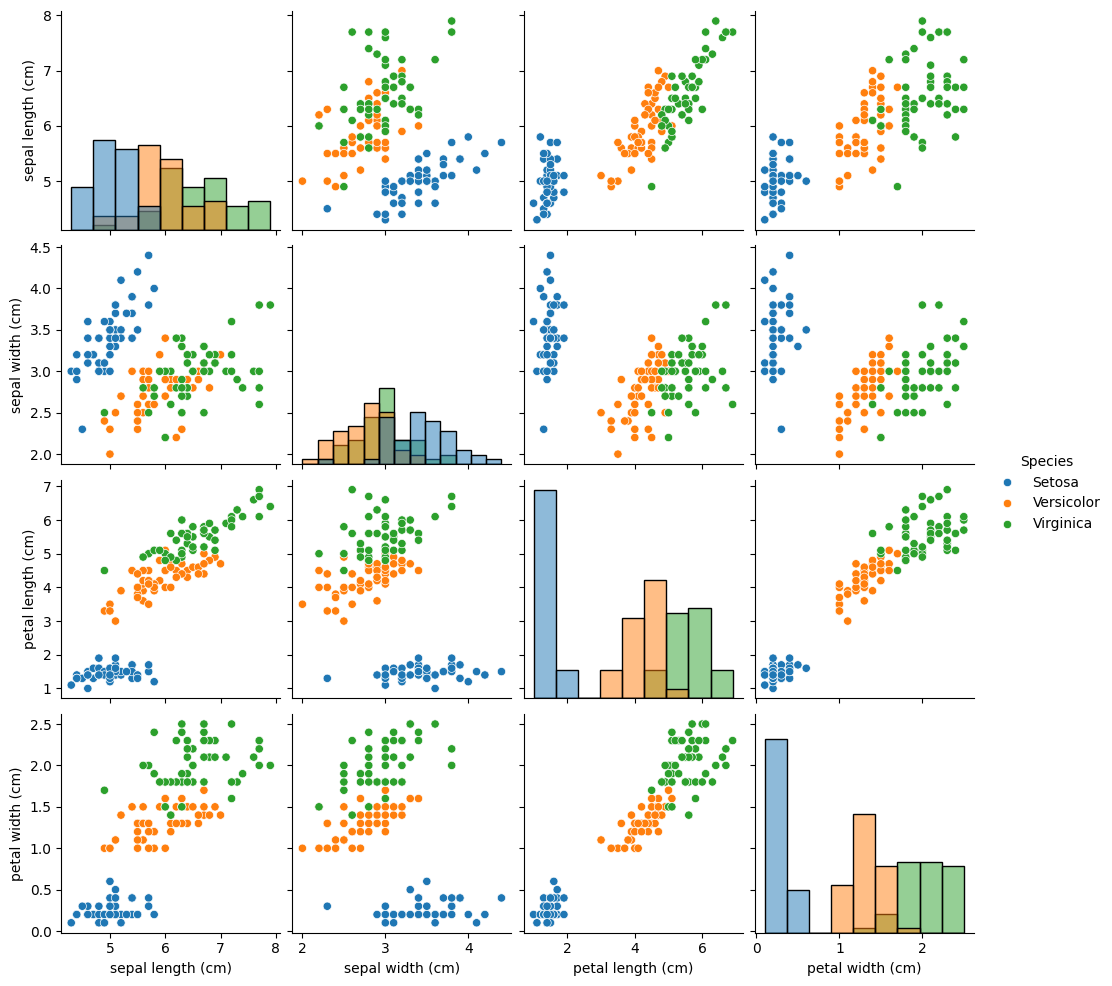

In [49]:
#Create a pair plot :-
sns.pairplot(
    df,
    hue="Species",
    diag_kind="hist"
)
plt.show()

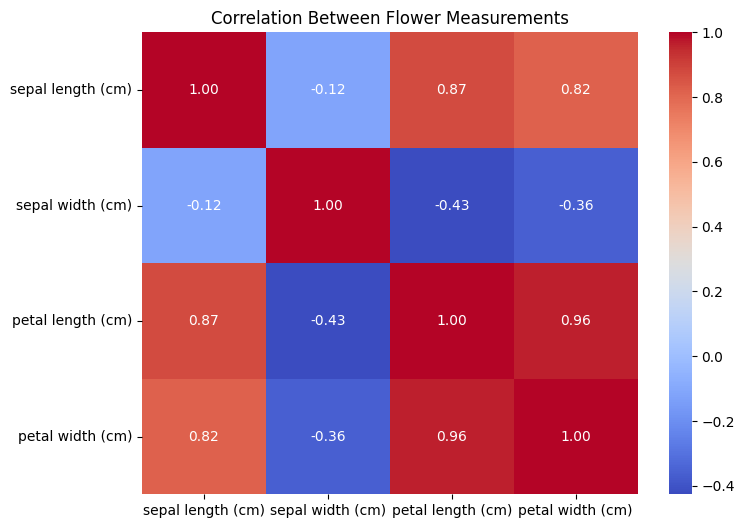

In [50]:
#Create a correlation heatmap :-
plt.figure(figsize=(8, 6))
correlation = df.drop(
    columns=["Species"]
).corr()
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Flower Measurements")
plt.show()

#Step 7 – Separate features and target

In [51]:
# Independent variables (Features) :-
X = df.drop("Species", axis=1)
# Dependent variable (Target) :-
y = df["Species"]
print("Features:")
print(X.head())
print("\nTarget:")
print(y.head())

Features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target:
0    Setosa
1    Setosa
2    Setosa
3    Setosa
4    Setosa
Name: Species, dtype: object


#Step 8 – Split the dataset into training and testing data

In [52]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (119, 4)
Testing data: (30, 4)


#Step 9 – Feature scaling

In [53]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Feature scaling completed!")

Feature scaling completed!


#Step 10 – Train Machine Learning models

In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create models :-
log_model = LogisticRegression(max_iter=1000)
knn_model = KNeighborsClassifier(n_neighbors=5)
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
print("Models created successfully!")

Models created successfully!


In [55]:
# Compare models using cross-validation :-
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Scaling is done inside the pipeline for Logistic Regression and KNN :-
log_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

# Random Forest does not require feature scaling :-
cv_scores = {
    "Logistic Regression": cross_val_score(
        log_pipeline, X_train, y_train, cv=cv, scoring="accuracy"
    ).mean(),
    "KNN": cross_val_score(
        knn_pipeline, X_train, y_train, cv=cv, scoring="accuracy"
    ).mean(),
    "Random Forest": cross_val_score(
        rf_model, X_train, y_train, cv=cv, scoring="accuracy"
    ).mean()
}

cv_results = pd.DataFrame({
    "Model": list(cv_scores.keys()),
    "Mean CV Accuracy": list(cv_scores.values())
})

cv_results["Mean CV Accuracy (%)"] = (
    cv_results["Mean CV Accuracy"] * 100
).round(2)

print("Cross-validation results:")
print(cv_results)

Cross-validation results:
                 Model  Mean CV Accuracy  Mean CV Accuracy (%)
0  Logistic Regression          0.965580                 96.56
1                  KNN          0.957246                 95.72
2        Random Forest          0.940217                 94.02


Train the models:

In [56]:
# Train Logistic Regression :-
log_model.fit(X_train_scaled, y_train)

# Train KNN :-
knn_model.fit(X_train_scaled, y_train)

# Train Random Forest :-
rf_model.fit(X_train, y_train)
print("All models trained successfully!")

All models trained successfully!


#Step 11 – Make predictions

In [57]:
# Predictions using each model :-
log_predictions = log_model.predict(X_test_scaled)
knn_predictions = knn_model.predict(X_test_scaled)
rf_predictions = rf_model.predict(X_test)

print("Logistic Regression Predictions:")
print(log_predictions)

print("\nKNN Predictions:")
print(knn_predictions)

print("\nRandom Forest Predictions:")
print(rf_predictions)

Logistic Regression Predictions:
['Versicolor' 'Versicolor' 'Virginica' 'Setosa' 'Virginica' 'Versicolor'
 'Versicolor' 'Setosa' 'Virginica' 'Virginica' 'Setosa' 'Setosa' 'Setosa'
 'Versicolor' 'Virginica' 'Setosa' 'Virginica' 'Setosa' 'Virginica'
 'Setosa' 'Versicolor' 'Versicolor' 'Setosa' 'Setosa' 'Versicolor'
 'Versicolor' 'Virginica' 'Virginica' 'Virginica' 'Versicolor']

KNN Predictions:
['Versicolor' 'Versicolor' 'Virginica' 'Setosa' 'Virginica' 'Versicolor'
 'Versicolor' 'Setosa' 'Versicolor' 'Virginica' 'Setosa' 'Setosa' 'Setosa'
 'Versicolor' 'Virginica' 'Setosa' 'Versicolor' 'Setosa' 'Virginica'
 'Setosa' 'Versicolor' 'Versicolor' 'Setosa' 'Setosa' 'Versicolor'
 'Versicolor' 'Virginica' 'Virginica' 'Virginica' 'Versicolor']

Random Forest Predictions:
['Versicolor' 'Versicolor' 'Virginica' 'Setosa' 'Virginica' 'Versicolor'
 'Versicolor' 'Setosa' 'Virginica' 'Virginica' 'Setosa' 'Setosa' 'Setosa'
 'Versicolor' 'Virginica' 'Setosa' 'Virginica' 'Setosa' 'Virginica'
 'Setosa' 'V

#Step 12 – Evaluate model accuracy

In [58]:
from sklearn.metrics import accuracy_score

# Calculate accuracy :-
log_accuracy = accuracy_score(
    y_test, log_predictions
)
knn_accuracy = accuracy_score(
    y_test, knn_predictions
)
rf_accuracy = accuracy_score(
    y_test, rf_predictions
)

print("Logistic Regression Accuracy:",
      round(log_accuracy * 100, 2), "%")

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 93.33 %
KNN Accuracy: 93.33 %
Random Forest Accuracy: 93.33 %


#Step 13 – Compare model performance

Let's create a comparison table.

In [59]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Random Forest"
    ],

    "Test Accuracy (%)": [
        log_accuracy * 100,
        knn_accuracy * 100,
        rf_accuracy * 100
    ],

    "Mean CV Accuracy (%)": [
        cv_scores["Logistic Regression"] * 100,
        cv_scores["KNN"] * 100,
        cv_scores["Random Forest"] * 100
    ]
})

results["Test Accuracy (%)"] = results["Test Accuracy (%)"].round(2)
results["Mean CV Accuracy (%)"] = results["Mean CV Accuracy (%)"].round(2)

print("Model Performance Comparison:")
print(results)

Model Performance Comparison:
                 Model  Test Accuracy (%)  Mean CV Accuracy (%)
0  Logistic Regression              93.33                 96.56
1                  KNN              93.33                 95.72
2        Random Forest              93.33                 94.02


Create a graph for test accuracy:

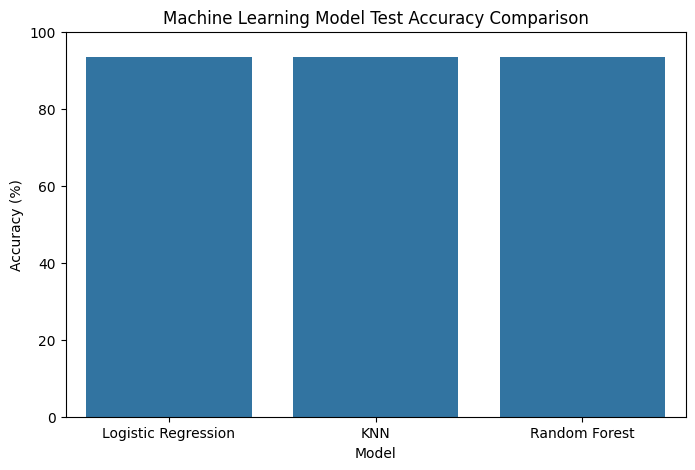

In [60]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=results,
    x="Model",
    y="Test Accuracy (%)"
)
plt.title("Machine Learning Model Test Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

#Step 14 – Select the best model

In [61]:
best_model_name = cv_results.loc[
    cv_results["Mean CV Accuracy"].idxmax(),
    "Model"
]
print("Best Performing Model (Cross-Validation):", best_model_name)

Best Performing Model (Cross-Validation): Logistic Regression


Select the model for further evaluation:

In [62]:
if best_model_name == "Logistic Regression":
    best_model = log_model
    X_evaluation = X_test_scaled

elif best_model_name == "KNN":
    best_model = knn_model
    X_evaluation = X_test_scaled

else:
    best_model = rf_model
    X_evaluation = X_test

#Step 15 – Confusion matrix

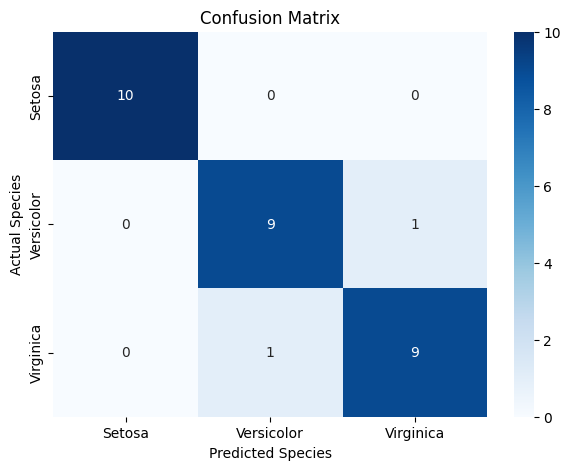

In [63]:
from sklearn.metrics import confusion_matrix
predictions = best_model.predict(X_evaluation)
cm = confusion_matrix(
    y_test,
    predictions,
    labels=["Setosa", "Versicolor", "Virginica"]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Setosa", "Versicolor", "Virginica"],
    yticklabels=["Setosa", "Versicolor", "Virginica"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

#Step 16 – Classification report

In [64]:
from sklearn.metrics import classification_report
print(
    classification_report(
        y_test,
        predictions
    )
)

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.90      0.90      0.90        10
   Virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



#Step 17 – Predict a new flower

In [65]:
# New flower measurements :-
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

# Predict species :-
if best_model_name in ["Logistic Regression", "KNN"]:
    new_flower_input = scaler.transform(new_flower)
else:
    new_flower_input = new_flower

prediction = best_model.predict(new_flower_input)
print("Predicted Flower Species:", prediction[0])

Predicted Flower Species: Setosa


#Step 18 – Save the trained model

In [66]:
import joblib
joblib.dump(best_model, "iris_model.pkl")
joblib.dump(scaler, "iris_scaler.pkl")
print("Model and scaler saved successfully!")

Model and scaler saved successfully!


Download the files:

In [67]:
from google.colab import files
files.download("iris_model.pkl")
files.download("iris_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Final project conclusion :-

Conclusion :-

The Iris Flower Classification project successfully demonstrates the application of Machine Learning for classifying flower species based on their physical measurements.

The project involved loading and exploring the Iris dataset, performing data preprocessing, visualizing feature relationships, splitting the dataset into training and testing sets, and training three classification algorithms: Logistic Regression, K-Nearest Neighbors, and Random Forest.

The models were evaluated using accuracy, confusion matrices, precision, recall, and F1-score.

The best-performing model was selected using cross-validation on the training data and then evaluated on the separate test data. It was used to predict the species of new Iris flowers.

Through this project, I gained practical experience in Python programming, data analysis, data visualization, and basic Machine Learning concepts.

Internship: CodeAlpha Data Science Internship

Task: Task 1 - Iris Flower Classification